# Assignment 7: Student Habits Data Analysis

Explore the supplied student habits dataset using Pandas and Matplotlib, then interpret the results.

## Load and preview the dataset

Import Pandas, read the CSV into the DataFrame `df`, and show the first five rows with `df.head()`.

In [1]:
from pathlib import Path
import pandas as pd

data_path = Path('class1_student_habits.csv')
df = pd.read_csv(data_path, keep_default_na=False, na_values=[""])
df.head()

,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,None,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,None,Yes,12,75.7,68.5


### Part 1: Brief answers

A Pandas DataFrame is a table with named columns. Each row in this dataset represents one student and records that student's habits and scores. Each column represents one type of information recorded for the students.


## Inspect the DataFrame structure

Show the total number of rows and columns. `df.info()` lists column names, data types, and non-null counts.

In [2]:
print(f'Rows: {len(df):,} | Columns: {df.shape[1]}')
df.info()

Rows: 250 | Columns: 10
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   student_id                    250 non-null    object 
 1   study_hours_per_week          241 non-null    float64
 2   sleep_hours_per_night         238 non-null    float64
 3   attendance_rate               250 non-null    float64
 4   practice_problems_per_week    250 non-null    int64  
 5   prior_programming_experience  243 non-null    object 
 6   study_group                   250 non-null    object 
 7   commute_minutes               250 non-null    int64  
 8   quiz_average                  250 non-null    float64
 9   exam_score                    250 non-null    float64
dtypes: float64(5), int64(2), object(3)
memory usage: 19.7+ KB


## Check dimensions and missing values

`df.shape` shows the number of rows and columns. `df.isna().sum()` counts missing entries in each column. `display()` shows both results from the same code cell.

The CSV import above keeps the literal `None` as a prior-programming-experience category while treating blank cells as missing.

In [3]:
display(df.shape)
display(df.isna().sum())

(250, 10)

student_id                       0
study_hours_per_week             9
sleep_hours_per_night           12
attendance_rate                  0
practice_problems_per_week       0
prior_programming_experience     7
study_group                      0
commute_minutes                  0
quiz_average                     0
exam_score                       0
dtype: int64

### Verify the prior-experience categories

The label `None` means no prior programming experience. The next cell shows that label separately from truly blank values, which Pandas displays as `NaN`.


In [4]:
display(df["prior_programming_experience"].value_counts(dropna=False))

prior_programming_experience
Some      107
None       88
Strong     48
NaN         7
Name: count, dtype: int64

### Part 2: Dataset structure answers

The numerical columns are `study_hours_per_week`, `sleep_hours_per_night`, `attendance_rate`, `practice_problems_per_week`, `commute_minutes`, `quiz_average`, and `exam_score`. The categorical columns are `prior_programming_experience` and `study_group`. `student_id` is an identifier.

Missing values occur in `study_hours_per_week` (9), `sleep_hours_per_night` (12), and `prior_programming_experience` (7). The other columns have no missing values.


## Examine numerical columns

Select columns containing numbers, preview their first few values, and count missing values in those columns.

In [5]:
numeric_df = df.select_dtypes(include="number")
display(numeric_df.head())
display(numeric_df.isna().sum())

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,commute_minutes,quiz_average,exam_score
0,1.3,7.7,71.8,8,0,67.0,64.6
1,9.4,6.6,74.2,14,52,74.8,81.5
2,11.2,6.1,70.3,15,7,99.1,92.0
3,10.8,7.6,77.1,16,12,86.4,100.0
4,8.0,5.6,89.7,15,12,75.7,68.5


study_hours_per_week           9
sleep_hours_per_night         12
attendance_rate                0
practice_problems_per_week     0
commute_minutes                0
quiz_average                   0
exam_score                     0
dtype: int64

## Calculate numerical summary statistics

`describe()` summarizes each numerical column with a count, mean, standard deviation, minimum, quartiles, and maximum.

In [6]:
numeric_df.describe()

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,commute_minutes,quiz_average,exam_score
count,241.000000,238.000000,250.000000,250.00000,250.000000,250.000000,250.000000
mean,7.500830,7.004622,85.468800,16.85600,24.428000,77.774400,77.159600
std,2.937544,1.042605,9.578326,9.56122,18.110682,10.515014,10.330499
min,0.300000,4.300000,54.400000,0.00000,0.000000,49.300000,51.400000
25%,5.300000,6.200000,78.900000,11.00000,11.250000,70.175000,69.500000
50%,7.500000,7.100000,85.750000,16.00000,23.000000,77.100000,76.950000
75%,9.500000,7.700000,92.575000,23.00000,36.000000,84.600000,84.975000
max,17.800000,10.000000,100.000000,78.00000,145.000000,100.000000,100.000000


### Part 3: Three observations

1. Among the 241 students with study hours recorded, the average is 7.5 hours per week. The values range from 0.3 to 17.8 hours, so students differ considerably in how much time they report studying.

2. Among the 238 students with sleep recorded, the average is about 7.0 hours per night. The range from 4.3 to 10.0 hours shows that sleep duration also varies across students.

3. Exam scores average 77.16 points and range from 51.4 to 100.0 points, showing a substantial difference between the lowest and highest scores.

In the `describe()` output above, the `50%` row is the median.


## Filter students by study time and attendance

Keep students who study at least 10 hours per week and have at least 90% attendance. Display their IDs, filter values, quiz averages, and exam scores.

In [7]:
students = df.loc[
    (df["study_hours_per_week"] >= 10) &
    (df["attendance_rate"] >= 90),
    ["student_id", "study_hours_per_week", "attendance_rate",
     "quiz_average", "exam_score"]
]

display(students)

,student_id,study_hours_per_week,attendance_rate,quiz_average,exam_score
9,S010,11.7,91.0,66.2,70.5
10,S011,11.1,94.5,76.3,75.9
22,S023,10.5,93.6,81.3,79.9
41,S042,10.7,98.2,100.0,96.2
54,S055,11.4,100.0,77.1,77.1
63,S064,11.7,94.6,93.7,94.1
108,S109,10.1,91.6,94.1,100.0
119,S120,11.0,90.7,95.0,98.8
167,S168,11.8,100.0,98.3,97.2
168,S169,12.3,93.2,94.1,96.8


## Find the 10 highest exam scores

Select the 10 students with the highest `exam_score` values. Show each student’s ID, exam and quiz scores, study hours, attendance, and practice problems for context.

In [8]:
top_10 = df.nlargest(10, "exam_score")[
    ["student_id", "exam_score", "quiz_average",
     "study_hours_per_week", "attendance_rate",
     "practice_problems_per_week"]
]

display(top_10)

,student_id,exam_score,quiz_average,study_hours_per_week,attendance_rate,practice_problems_per_week
3,S004,100.0,86.4,10.8,77.1,16
108,S109,100.0,94.1,10.1,91.6,25
223,S224,100.0,83.4,16.2,84.7,13
215,S216,99.0,96.4,9.0,100.0,15
119,S120,98.8,95.0,11.0,90.7,8
143,S144,97.5,88.1,9.1,96.6,16
167,S168,97.2,98.3,11.8,100.0,19
168,S169,96.8,94.1,12.3,93.2,21
139,S140,96.6,92.3,7.3,100.0,31
231,S232,96.5,84.5,5.1,93.4,15


## Check study-group categories

Count how many students are in each `study_group` category. `dropna=False` would also show a missing category if one existed.

In [9]:
display(df["study_group"].value_counts(dropna=False))

study_group
Yes    129
No     121
Name: count, dtype: int64

## Compare exam scores by study group

Group students by study-group participation, then calculate the number of students, mean exam score, and median exam score for each group.

In [10]:
study_group_summary = (
    df.groupby("study_group")
      .agg(
          number_of_students=("student_id", "size"),
          mean_exam_score=("exam_score", "mean"),
          median_exam_score=("exam_score", "median")
      )
      .reset_index()
)

display(study_group_summary.round(2))

,study_group,number_of_students,mean_exam_score,median_exam_score
0,No,121,76.87,75.9
1,Yes,129,77.43,77.7


### Part 4: Group comparison observation

Students who participate in a study group averaged 77.43 on the exam, compared with 76.87 for students who do not, a difference of 0.56 points. Their median scores were 77.7 and 75.9, respectively. These differences do not establish that study-group participation caused higher exam scores.


## Visualization 1: Exam score histogram

This histogram groups exam scores into ranges. Each bar shows how many students scored within that range; missing scores are omitted.

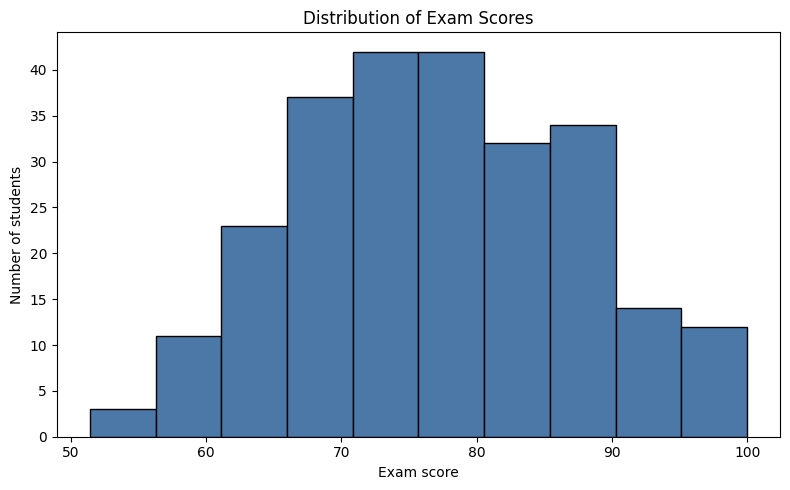

In [11]:
import matplotlib.pyplot as plt

scores = df["exam_score"].dropna()
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(scores, bins=10, color="#4C78A8", edgecolor="black")
ax.set_title("Distribution of Exam Scores")
ax.set_xlabel("Exam score")
ax.set_ylabel("Number of students")
fig.tight_layout()
plt.show()

### Interpretation

Most exam scores fall between roughly 65 and 90, with the tallest bars in the 70s. Scores near the low 50s and upper 90s are less common.

## Visualization 2: Study hours and exam score scatter plot

**Prediction for Part 6:** I expect study hours per week to be positively associated with exam score because more time studying may help students prepare for the test.

Each dot represents one student: weekly study hours on the horizontal axis and exam score on the vertical axis. Students missing either value are omitted.

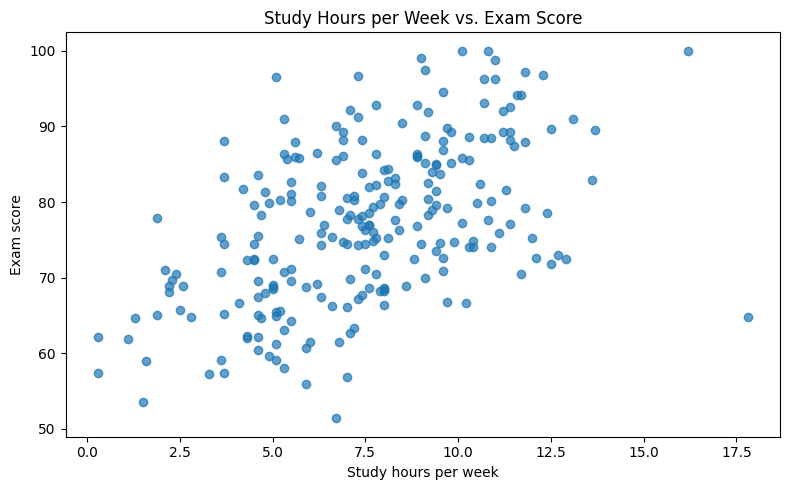

In [12]:
import matplotlib.pyplot as plt

plot_df = df.dropna(subset=["study_hours_per_week", "exam_score"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    plot_df["study_hours_per_week"],
    plot_df["exam_score"],
    alpha=0.7
)

ax.set_title("Study Hours per Week vs. Exam Score")
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Exam score")
fig.tight_layout()
plt.show()

### Interpretation

The points generally trend upward: students reporting more weekly study hours often have higher exam scores. There is substantial spread at similar study times, so study hours alone do not determine a student's score.

## Visualization 3: Sleep and exam score scatter plot

Each dot represents one student, with hours of sleep per night on the horizontal axis and exam score on the vertical axis. Students missing either value are omitted.

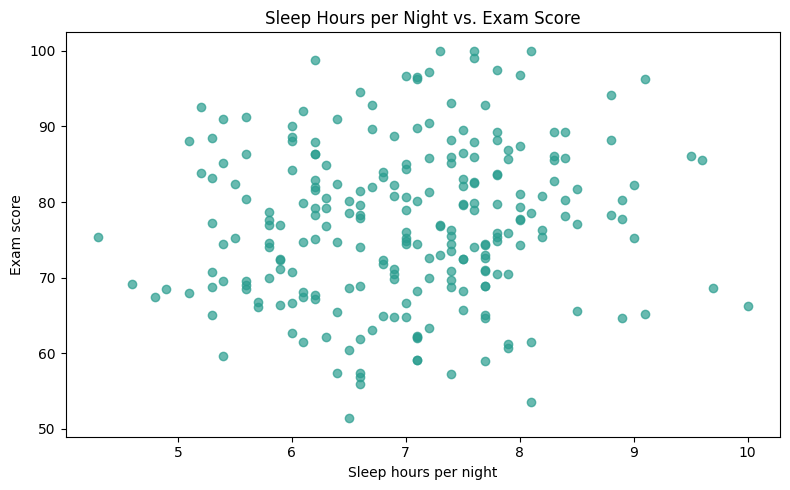

In [13]:
import matplotlib.pyplot as plt

sleep_plot_df = df.dropna(subset=["sleep_hours_per_night", "exam_score"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    sleep_plot_df["sleep_hours_per_night"],
    sleep_plot_df["exam_score"],
    alpha=0.7,
    color="#2A9D8F"
)

ax.set_title("Sleep Hours per Night vs. Exam Score")
ax.set_xlabel("Sleep hours per night")
ax.set_ylabel("Exam score")
fig.tight_layout()
plt.show()

### Interpretation

Exam scores vary widely at nearly every sleep duration, with no strong upward or downward pattern in the dots. In this dataset, sleep hours alone do not clearly distinguish students with high exam scores from those with low scores.

## Part 6: Investigate study hours and exam score

The prediction for this relationship appears above Visualization 2, before the first study-hours/exam-score scatter plot.

**Visualization:** The scatter plot directly below revisits the relationship, with one dot per student who has both values.

### Visualize the predicted relationship

This scatter plot follows the prediction above and shows study hours per week against exam score.


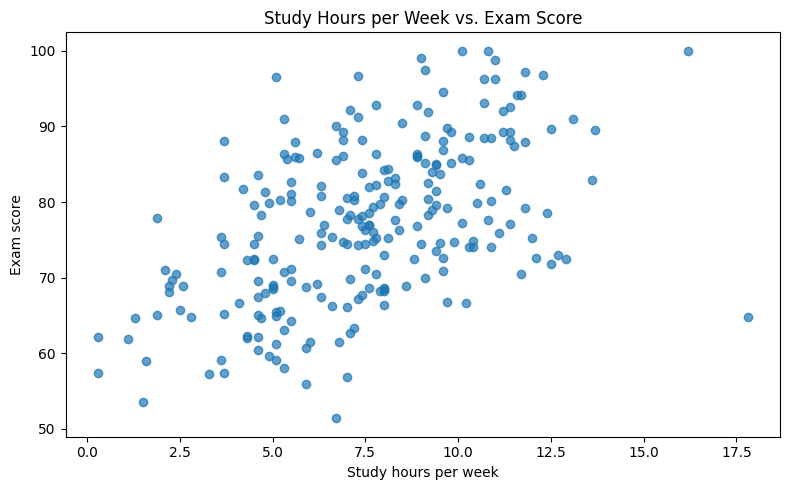

In [14]:
import matplotlib.pyplot as plt

plot_df = df.dropna(subset=["study_hours_per_week", "exam_score"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    plot_df["study_hours_per_week"],
    plot_df["exam_score"],
    alpha=0.7
)

ax.set_title("Study Hours per Week vs. Exam Score")
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Exam score")
fig.tight_layout()
plt.show()

In [15]:
relationship_df = df[["study_hours_per_week", "exam_score"]].dropna()
correlation = relationship_df["study_hours_per_week"].corr(
    relationship_df["exam_score"], method="pearson"
)
print(f"Students analyzed: {len(relationship_df)}")
print(f"Pearson correlation: {correlation:+.3f}")

Students analyzed: 241
Pearson correlation: +0.516


### Interpretation

For the 241 students with both values, the Pearson correlation is +0.516. This is a moderate positive linear association: students who report more study hours tend to have higher exam scores, though scores vary at similar study times. This comparison does not show that extra study hours caused the score differences.

## Additional question: Are study hours associated with sleep?

**Question:** Are weekly study hours associated with hours of sleep per night?

**Prediction:** Students who study more might sleep less if studying takes up their time, but students with strong routines might study more and still protect their sleep. The direction of the relationship is uncertain.

**Data and method:** Use `study_hours_per_week` and `sleep_hours_per_night`, keep students with both measurements, inspect a scatter plot, and calculate Pearson correlation.

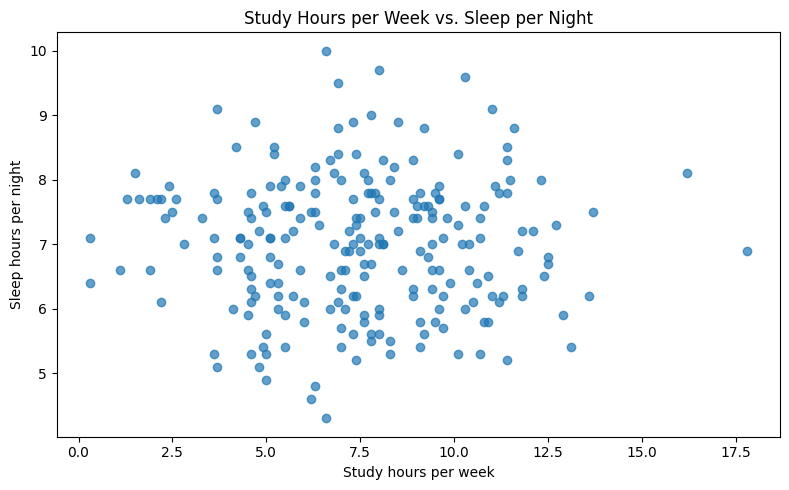

Students analyzed: 230
Pearson correlation: -0.004


In [16]:
import matplotlib.pyplot as plt

study_sleep = df[
    ["study_hours_per_week", "sleep_hours_per_night"]
].dropna()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    study_sleep["study_hours_per_week"],
    study_sleep["sleep_hours_per_night"],
    alpha=0.7
)
ax.set_title("Study Hours per Week vs. Sleep per Night")
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Sleep hours per night")
fig.tight_layout()
plt.show()

correlation = study_sleep["study_hours_per_week"].corr(
    study_sleep["sleep_hours_per_night"],
    method="pearson"
)
print(f"Students analyzed: {len(study_sleep)}")
print(f"Pearson correlation: {correlation:+.3f}")

### Conclusion

For the 230 students with both measurements, Pearson correlation is -0.004, effectively zero. The scatter plot shows a wide range of sleep durations at similar study times and no clear upward or downward pattern. In this sample, more study hours do not consistently go with either more or less sleep; this analysis also cannot establish whether studying changes sleep.

## AI Reflection

**AI contribution:** AI helped me use Pandas to investigate missing values and explained why `None` should remain a category for prior programming experience. Its explanations also helped me understand Pandas and Matplotlib syntax that was new to me.

**My verification:** I reviewed the AI-generated code to check that it used the intended columns. I also compared the prior-experience category counts with the missing-value summary: the category count shows 88 entries labeled `None` and 7 missing entries, matching the summary's count of 7 missing values.

**What I learned:** I learned that Pandas CSV import settings can change how categorical text is interpreted. I should check unusual results against the original data instead of assuming the first output is correct. This assignment also reminded me of a problem in my data science class: a misunderstanding with AI led us to train a model longer even though its results were not improving. That experience reinforced the importance of rereading assignment directions and checking results instead of repeatedly following suggestions based on a misunderstanding.


